# Метод опорных векторов (SVM) и ядра

# Цели обучения

- Применение метода опорных векторов (SVM) — популярного алгоритма, используемого для задач классификации.
- Выявление сходства SVM с логистической регрессией.
- Вычисление функции потерь для SVM.
- Применение регуляризации в SVM и изучение способов получения нелинейной классификации с помощью SVM.

## Введение

В работе используется набор данных о качестве вина (`Wine_Quality_Data.csv`). Он содержит химические свойства вина (кислотность, содержание сахара, pH, содержание алкоголя и др.), оценку качества (от 3 до 9, где более высокий балл означает лучшее качество) и цвет вина (красное или белое).

Задача состоит в том, чтобы научиться отличать красное вино от белого с помощью SVM, сравнить линейное и гауссовское (RBF) ядра и оценить выигрыш по времени от аппроксимации ядра методом Нистрёма.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('scikit-learn-intelex не установлен — используется стандартный scikit-learn')

%matplotlib inline

scikit-learn-intelex не установлен — используется стандартный scikit-learn


## Вопрос 1. Подготовка данных

На данном этапе выполняется:

- импорт данных;
- создание целевой переменной `y` в виде столбца 1/0, где 1 означает красное вино;
- построение парного графика (pairplot) для набора данных;
- построение столбчатой диаграммы корреляции каждого столбца с `y`;
- выбор двух признаков с наибольшей по модулю корреляцией и формирование из них матрицы `X`;
- масштабирование `X` с помощью `MinMaxScaler`. Результатом масштабирования является `np.array`, поэтому он снова преобразуется в `DataFrame` с соответствующими названиями столбцов.

In [2]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data - Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
# Целевая переменная: 1 — красное вино, 0 — белое
y = (data.color == 'red').astype(int)
y.value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

Парный график: по диагонали показаны распределения признаков, вне диагонали — диаграммы рассеяния для каждой пары. Цветом выделен цвет вина.

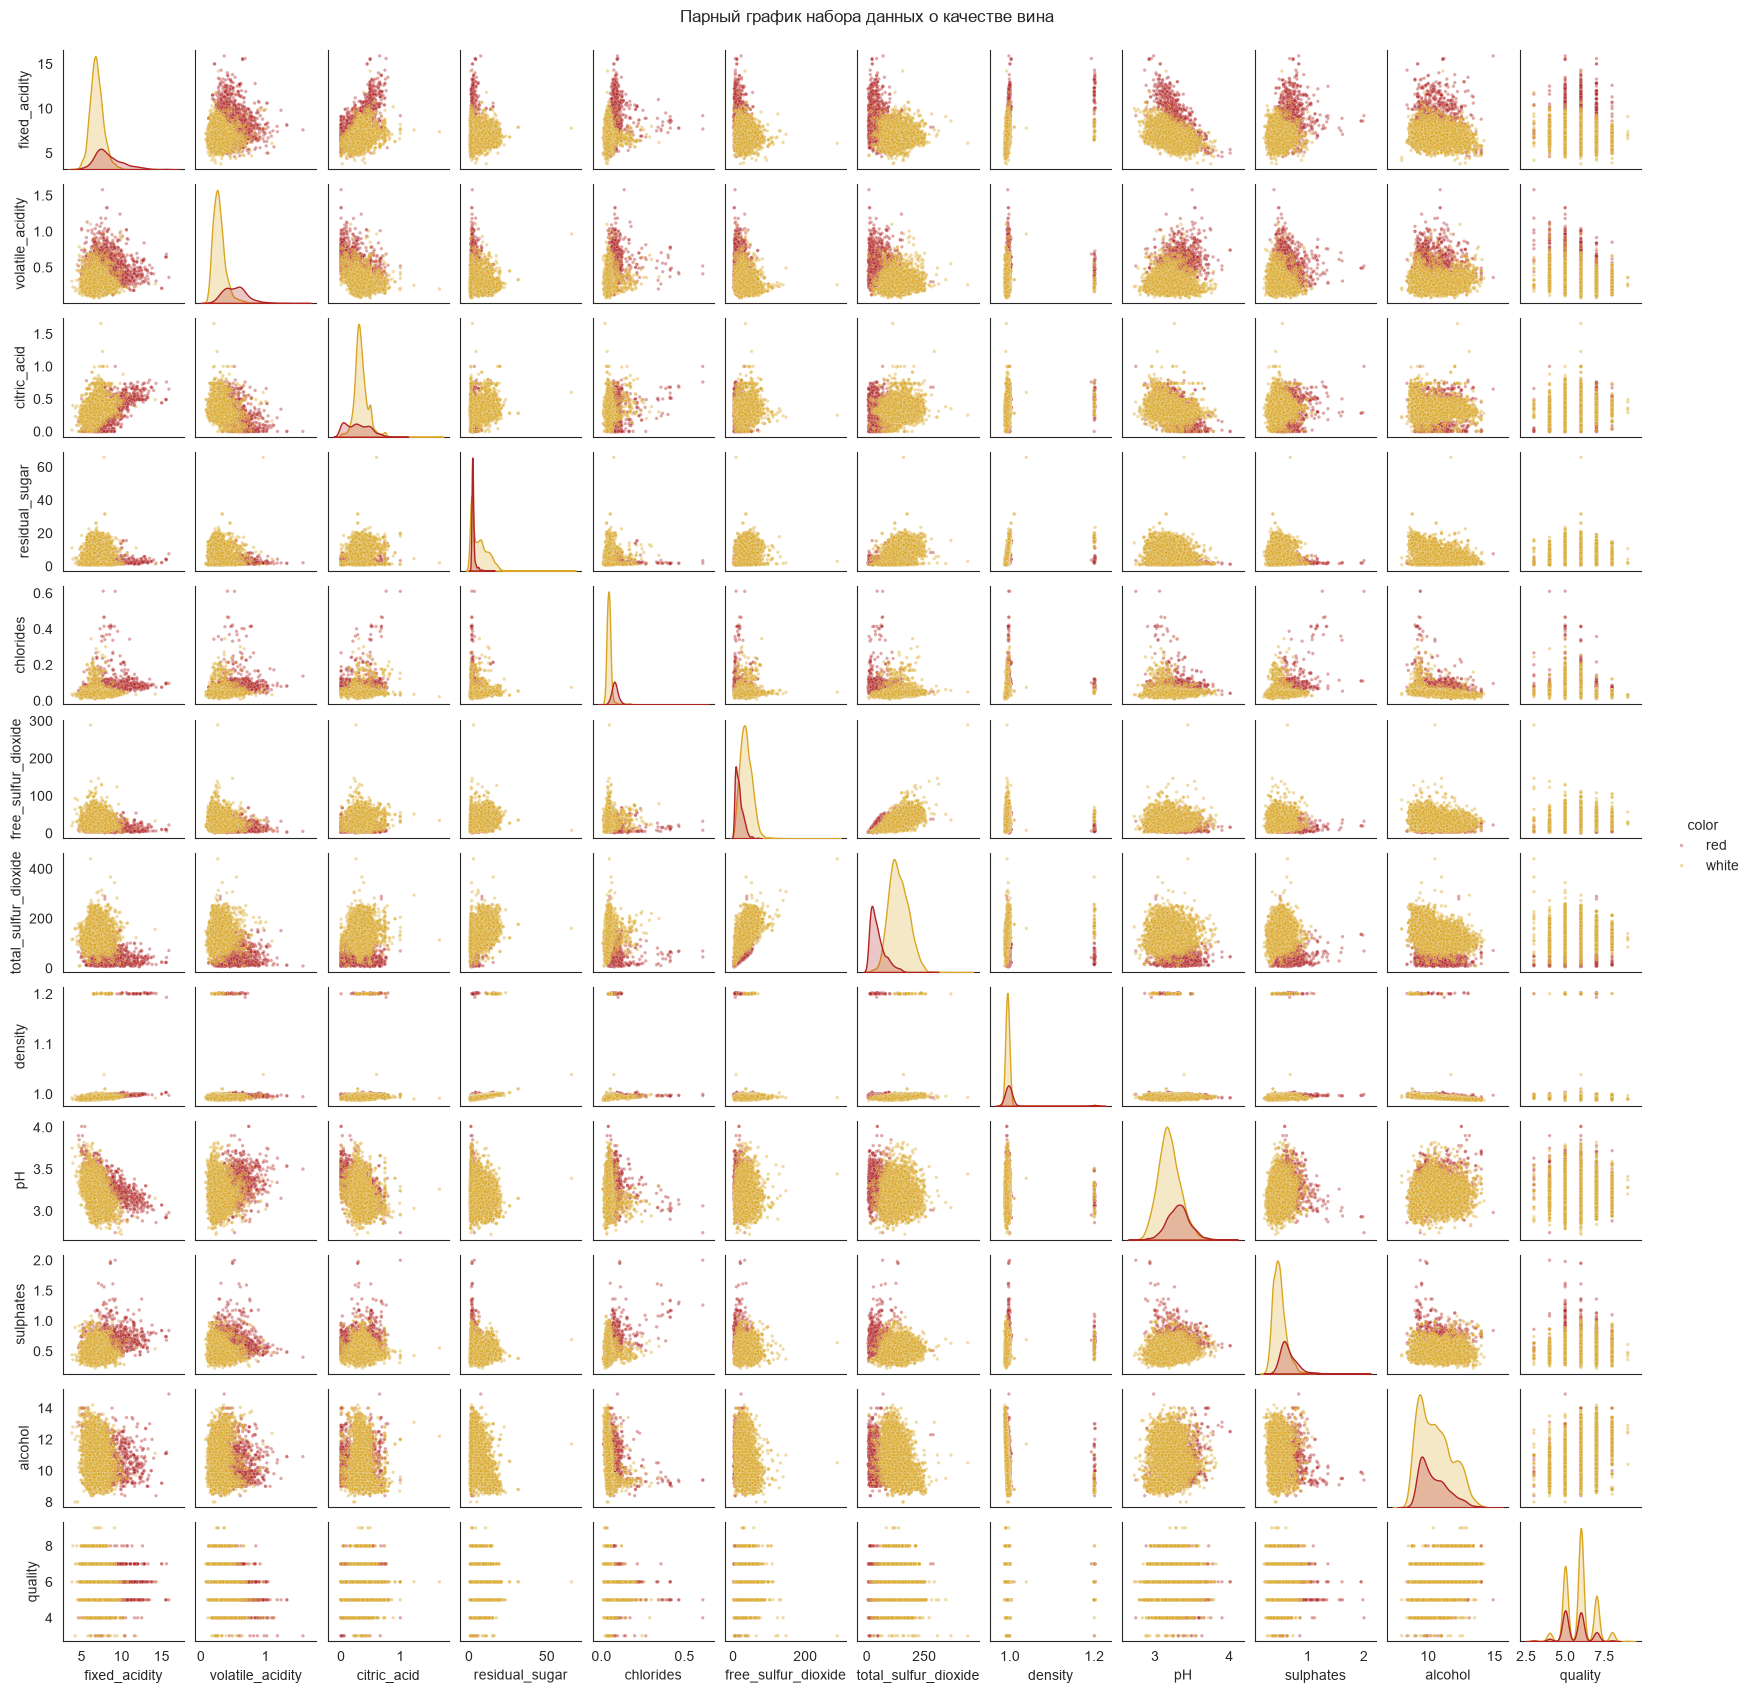

In [4]:
sns.set_style('white')
g = sns.pairplot(data, hue='color', palette={'red': 'firebrick', 'white': 'goldenrod'},
                 plot_kws={'s': 6, 'alpha': 0.4}, height=1.4)
g.figure.suptitle('Парный график набора данных о качестве вина', y=1.01);

Корреляция каждого числового признака с целевой переменной `y`.

total_sulfur_dioxide   -0.700357
free_sulfur_dioxide    -0.471644
residual_sugar         -0.348821
citric_acid            -0.187397
quality                -0.119323
alcohol                -0.032970
density                 0.122033
pH                      0.329129
fixed_acidity           0.486740
sulphates               0.487218
chlorides               0.512678
volatile_acidity        0.653036
dtype: float64

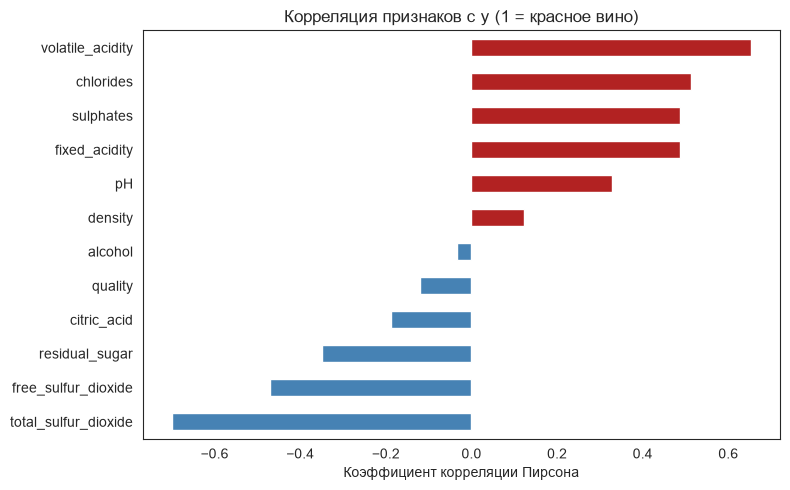

In [5]:
features_all = data.drop(columns='color')
correlations = features_all.corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
correlations.plot.barh(ax=ax, color=['firebrick' if v > 0 else 'steelblue' for v in correlations])
ax.set(title='Корреляция признаков с y (1 = красное вино)', xlabel='Коэффициент корреляции Пирсона')
plt.tight_layout()
correlations

In [6]:
# Два признака с наибольшей абсолютной корреляцией
top2 = correlations.abs().sort_values(ascending=False).index[:2].tolist()
print('Выбранные признаки:', top2)
print(correlations[top2])

X_raw = data[top2]

# MinMaxScaler возвращает np.array — возвращаем DataFrame с прежними названиями столбцов
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=top2)
X.describe().loc[['min', 'max']]

Выбранные признаки: ['total_sulfur_dioxide', 'volatile_acidity']
total_sulfur_dioxide   -0.700357
volatile_acidity        0.653036
dtype: float64


,total_sulfur_dioxide,volatile_acidity
min,0.0,0.0
max,1.0,1.0


### Выводы к вопросу 1

* **Данные:** набор содержит 6 497 записей и 13 столбцов. Красных вин 1 599 (≈ 24,6 %), белых — 4 898 (≈ 75,4 %), то есть классы несбалансированы. Это важно для интерпретации точности: классификатор, всегда отвечающий «белое», уже давал бы ≈ 75 %.
* **Парный график** показывает, что по ряду признаков красные и белые вина разделяются заметно (в частности, по содержанию диоксида серы и летучей кислотности), тогда как по другим (например, `alcohol`, `quality`) облака точек почти полностью перекрываются.
* **Корреляция с `y`:** сильнее всего с цветом связаны `total_sulfur_dioxide` (−0,70) и `volatile_acidity` (+0,65); следующие за ними `chlorides` (0,51), `sulphates` (0,49) и `fixed_acidity` (0,49) заметно слабее. Красные вина содержат меньше диоксида серы и больше летучей кислотности.
* **Выбор признаков:** по абсолютной корреляции выбраны `total_sulfur_dioxide` и `volatile_acidity`. Выбор именно двух признаков позволяет отображать границу решения на плоскости.
* **Масштабирование:** после `MinMaxScaler` оба признака лежат в диапазоне [0; 1] (min = 0, max = 1). Для SVM это необходимо, так как алгоритм опирается на расстояния и скалярные произведения, и признак с большим числовым масштабом иначе доминировал бы. Кроме того, сетка для графиков в дальнейших вопросах задана именно на отрезке [0; 1].

## Вопрос 2. Граница принятия решения LinearSVC

Целью данного этапа является анализ границы принятия решения классификатора `LinearSVC` для выбранного набора данных (по аналогии с [примером из документации sklearn](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py)).

На данном этапе выполняется:

- обучение классификатора линейного метода опорных векторов на `X`, `y`;
- выбор 300 случайных образцов из `X` и соответствующих значений `y`, которые сохраняются в `X_color` и `y_color` (исходный набор слишком велик, и график получился бы перегруженным);
- замена в `y_color` значения 1 на «red» и значения 0 на «yellow»;
- построение диаграммы рассеяния для столбцов `X_color` с передачей `color=y_color`;
- отрисовка поверхности решения на сетке точек с помощью `ax.contourf`;
- эксперименты с различными значениями параметров `LinearSVC` и сравнение получающихся границ.

In [7]:
linear_svc = LinearSVC(random_state=42).fit(X, y)
print('Точность на всех данных:', round(linear_svc.score(X, y), 4))
print('Коэффициенты w:', linear_svc.coef_.round(2), ' смещение b:', linear_svc.intercept_.round(2))

Точность на всех данных: 0.9546
Коэффициенты w: [[-7.45  5.17]]  смещение b: [0.07]


In [8]:
# Выборка из 300 образцов для наглядного графика
X_color = X.sample(300, random_state=42)
y_color = y.loc[X_color.index]
y_color = y_color.replace({1: 'red', 0: 'yellow'})
y_color.value_counts()

color
yellow    229
red        71
Name: count, dtype: int64

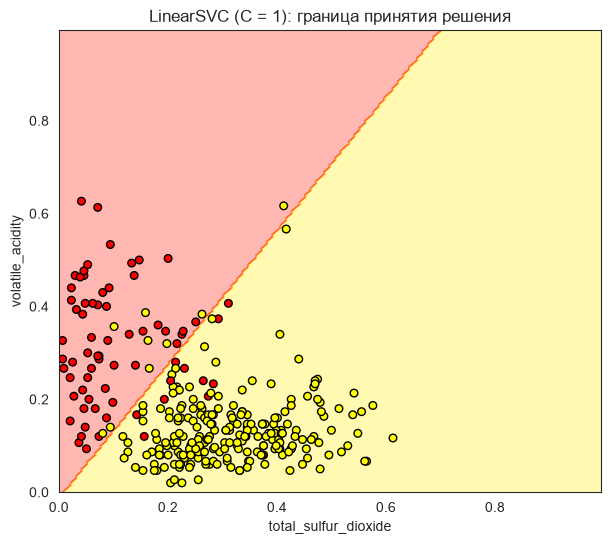

In [9]:
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns

fig, ax = plt.subplots(figsize=(7, 6))
y_grid_predictions = linear_svc.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolor='k', s=30)
ax.set(xlabel=X.columns[0], ylabel=X.columns[1], title='LinearSVC (C = 1): граница принятия решения');

Эксперимент с параметром регуляризации `C`: малое `C` — сильная регуляризация (широкая «полоса», допускаются ошибки), большое `C` — слабая регуляризация (штраф за ошибки велик).

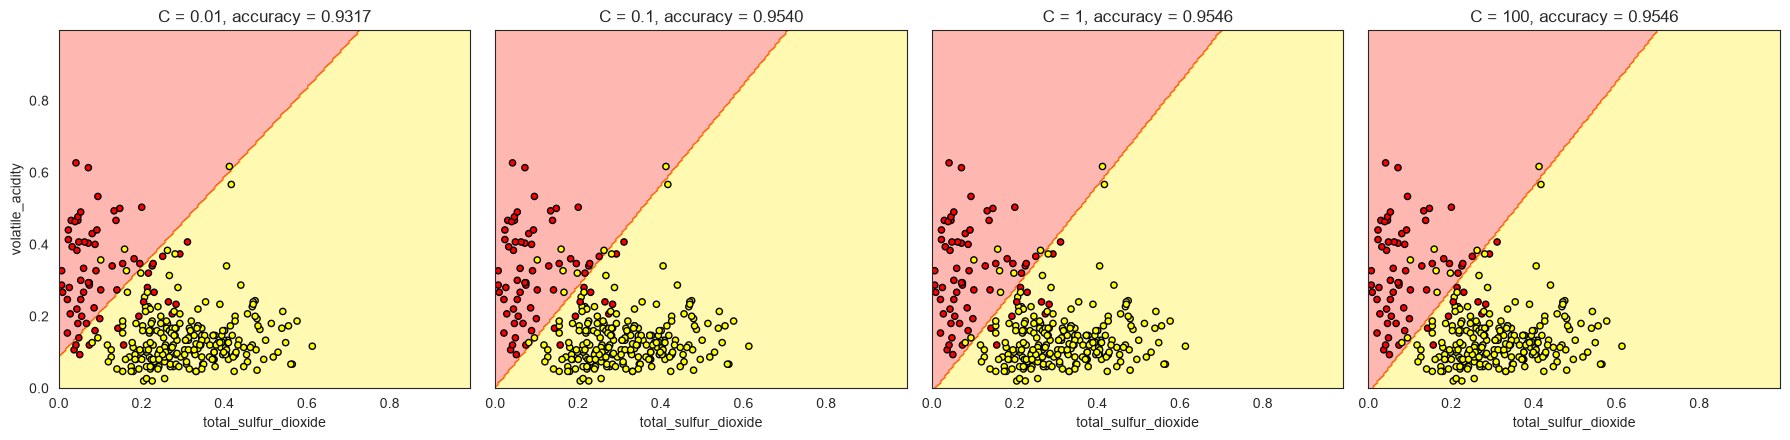

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, C in zip(axes, [0.01, 0.1, 1, 100]):
    m = LinearSVC(C=C, random_state=42, max_iter=10000).fit(X, y)
    pred = m.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, pred, cmap=plt.cm.autumn_r, alpha=.3)
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolor='k', s=20)
    ax.set(title=f'C = {C}, accuracy = {m.score(X, y):.4f}', xlabel=X.columns[0])
axes[0].set_ylabel(X.columns[1])
plt.tight_layout()

### Выводы к вопросу 2

* `LinearSVC` строит **прямую** границу: коэффициенты `w ≈ (−7,45; 5,17)`, смещение `b ≈ 0,07`. Знаки соответствуют корреляциям: чем больше диоксида серы, тем вероятнее белое вино; чем больше летучей кислотности, тем вероятнее красное.
* Точность на всех данных составила **0,9546**. С учётом доли белого вина 75 % это содержательный результат: две химические характеристики практически достаточны для определения цвета.
* **Влияние `C`.** При `C = 0,01` (сильная регуляризация) точность падает до 0,9317 — модель слишком «жёсткая»; уже при `C = 0,1` она достигает 0,9540, а при `C = 1` и `C = 100` результат одинаков (0,9546). Дальнейшее увеличение `C` не меняет границу, потому что оставшиеся ошибки лежат в зоне перекрытия классов и линейно неустранимы.
* Ошибочно классифицируются в основном точки возле границы, где красные и белые образцы смешаны.

## Вопрос 3. SVC с гауссовским ядром

На данном этапе гауссовское ядро (RBF) применяется в классификаторе `SVC`, и анализируется, как при этом изменяется граница решения.

Для этого выполняется:

- объединение кода из вопроса 2 в одну функцию, принимающую оценщик (`estimator`), `X` и `y`. Функция обучает модель, берёт выборку из 300 записей с соответствующими `y`, строит сетку, получает предсказания, рисует поверхность решения через `ax.contourf` и накладывает диаграмму рассеяния. В готовой функции используется переданный `estimator`, а не ранее созданная модель `LinearSVC`;
- построение границы решения для гауссовского ядра при `gamma = [.5, 1, 2, 10]`;
- построение границы решения при фиксированном `gamma` и различных значениях `C = [.1, 1, 10]`.

In [ ]:
def plot_decision_boundary(estimator, X, y, ax=None, n_samples=300, random_state=42, title=None):
    # 1. подгонка модели
    estimator.fit(X, y)

    # 2. выборка 300 записей и соответствующих y
    X_c = X.sample(n_samples, random_state=random_state)
    y_c = y.loc[X_c.index].replace({1: 'red', 0: 'yellow'})

    # 3. сетка, предсказания, contourf
    xs, ys = np.arange(0, 1, .005), np.arange(0, 1, .005)
    gx, gy = np.meshgrid(xs, ys)
    grid = pd.DataFrame([gx.ravel(), gy.ravel()]).T
    grid.columns = X.columns
    pred = estimator.predict(grid).reshape(gx.shape)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(gx, gy, pred, cmap=plt.cm.autumn_r, alpha=.3)

    # 4. рассеяние поверх поверхности решения
    ax.scatter(X_c.iloc[:, 0], X_c.iloc[:, 1], color=y_c, edgecolor='k', s=20)
    ax.set(xlabel=X.columns[0], title=title)
    return estimator

,gamma,accuracy,n_support
0,0.5,0.955364,1067
1,1.0,0.954748,955
2,2.0,0.954748,877
3,10.0,0.955056,775


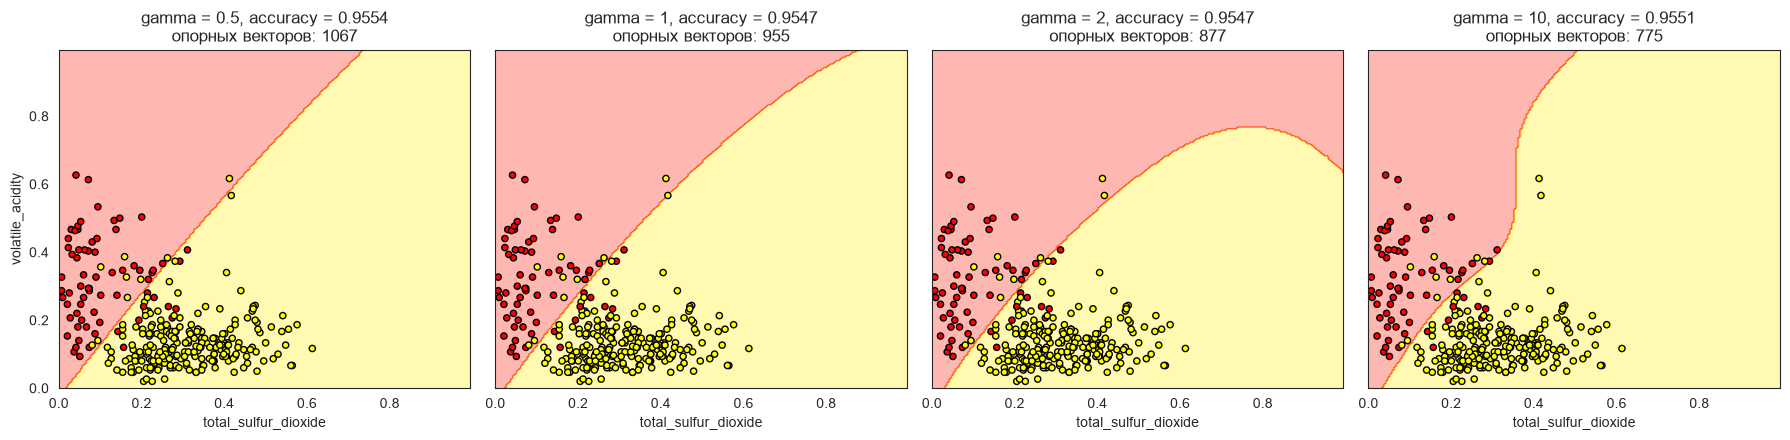

In [12]:
gammas = [.5, 1, 2, 10]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
gamma_info = []
for ax, g in zip(axes, gammas):
    m = plot_decision_boundary(SVC(kernel='rbf', gamma=g, C=1), X, y, ax=ax)
    acc = m.score(X, y)
    gamma_info.append((g, acc, m.n_support_.sum()))
    ax.set_title(f'gamma = {g}, accuracy = {acc:.4f}\nопорных векторов: {m.n_support_.sum()}')
axes[0].set_ylabel(X.columns[1])
plt.tight_layout()
pd.DataFrame(gamma_info, columns=['gamma', 'accuracy', 'n_support'])

,C,accuracy,n_support
0,0.1,0.953671,1578
1,1.0,0.954748,955
2,10.0,0.955056,806


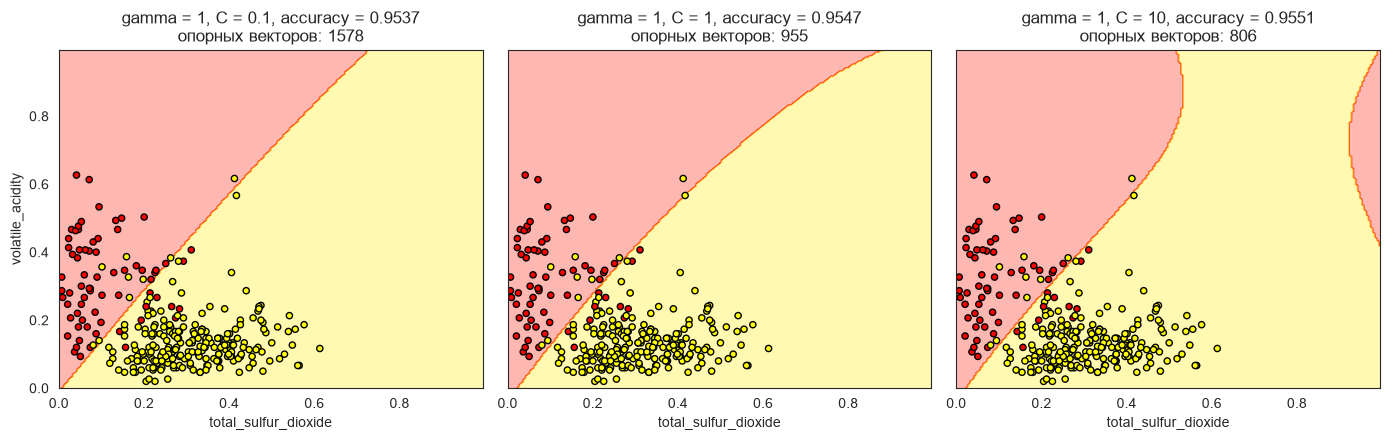

In [13]:
Cs = [.1, 1, 10]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
c_info = []
for ax, C in zip(axes, Cs):
    m = plot_decision_boundary(SVC(kernel='rbf', gamma=1, C=C), X, y, ax=ax)
    acc = m.score(X, y)
    c_info.append((C, acc, m.n_support_.sum()))
    ax.set_title(f'gamma = 1, C = {C}, accuracy = {acc:.4f}\nопорных векторов: {m.n_support_.sum()}')
axes[0].set_ylabel(X.columns[1])
plt.tight_layout()
pd.DataFrame(c_info, columns=['C', 'accuracy', 'n_support'])

### Выводы к вопросу 3

* Функция `plot_decision_boundary(estimator, X, y)` объединяет все шаги (обучение, выборка 300 точек, сетка, `contourf`, диаграмма рассеяния) и работает с любым переданным оценщиком.
* **Влияние `gamma`** (при `C = 1`). Параметр определяет «радиус влияния» одного объекта. При малой `gamma` (0,5) граница почти плоская и гладкая, похожая на линейную; при увеличении `gamma` она становится всё более изогнутой и локальной, а при `gamma = 10` в правой части появляется резкий излом, подгоняющийся под отдельные группы точек. Это путь к переобучению: чрезмерно большая `gamma` делает модель слишком чувствительной к шуму. Число опорных векторов при этом уменьшается: 1 067 → 955 → 877 → 775.
* **Влияние `C`** (при `gamma = 1`). Точность растёт слабо (0,9537 → 0,9547 → 0,9551), но число опорных векторов заметно падает (1 578 → 955 → 806): при малом `C` допускается много нарушений отступа и почти каждая точка в зоне перекрытия становится опорной; при большом `C` модель сильнее штрафует ошибки и подстраивается под обучающие данные.
* **Главное наблюдение:** точность всех вариантов гауссовского ядра (≈ 0,955) практически совпадает с точностью линейной модели (0,9546). Для этих двух признаков классы разделяются почти линейно, поэтому нелинейное ядро не даёт выигрыша, а лишь усложняет границу. Нелинейность оправдана, когда классы действительно не разделимы прямой.

## Вопрос 4. Сравнение времени обучения: SVC и Nystroem + SGD

На данном этапе сравнивается время обучения `SVC` с ядром RBF и комбинации «аппроксимация ядра методом Нистрёма (`Nystroem`) + `SGDClassifier`». Для замера времени используется магическая команда Jupyter **`%%timeit`**, которая многократно запускает ячейку и выводит среднее время выполнения.

Последовательность действий:

- повторная загрузка данных о качестве вина (на случай изменений исходного набора);
- создание `y` из `data.color` и `X` из остальных столбцов;
- замер времени обучения `SVC` с ядром rbf;
- замер времени для связки: преобразование данных с помощью `Nystroem`, затем обучение `SGDClassifier`;
- создание 5 копий `X` и 5 копий `y` и их объединение (увеличение выборки в 5 раз);
- повторное сравнение времени обучения обоих методов на увеличенной выборке.

Ожидается, что Nystroem + SGD потребует существенно меньше времени, причём разница будет заметнее на большем наборе данных.

In [14]:
data = pd.read_csv(filepath)
y = (data.color == 'red').astype(int)
X = data.drop(columns='color')

# SVM чувствителен к масштабу признаков — приводим все признаки к [0, 1]
X = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)
print(X.shape, y.shape)

(6497, 12) (6497,)


Время обучения `SVC` с ядром rbf на исходном наборе (6 497 записей).

In [15]:
%%timeit -n 1 -r 3
SVC(kernel='rbf', gamma=1, C=1).fit(X, y)

32.3 ms ± 408 μs per loop (mean ± std. dev. of 3 runs, 1 loop each)


Время для связки `Nystroem` (аппроксимация ядра 100 компонентами) + `SGDClassifier` на исходном наборе.

In [16]:
%%timeit -n 1 -r 3
nys = Nystroem(kernel='rbf', gamma=1, n_components=100, random_state=42)
X_nys = nys.fit_transform(X)
SGDClassifier(max_iter=1000, tol=1e-3, random_state=42).fit(X_nys, y)

15 ms ± 3.95 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [17]:
# Качество обоих подходов на исходном наборе (для сопоставления с затраченным временем)
svc = SVC(kernel='rbf', gamma=1, C=1).fit(X, y)
nys = Nystroem(kernel='rbf', gamma=1, n_components=100, random_state=42)
X_nys = nys.fit_transform(X)
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42).fit(X_nys, y)
print('SVC (rbf)       accuracy:', round(svc.score(X, y), 4))
print('Nystroem + SGD  accuracy:', round(sgd.score(X_nys, y), 4))

SVC (rbf)       accuracy: 0.9929
Nystroem + SGD  accuracy: 0.9922


Увеличение выборки: 5 копий `X` и 5 копий `y`, объединённые в один набор (32 485 записей).

In [18]:
X_big = pd.concat([X] * 5, ignore_index=True)
y_big = pd.concat([y] * 5, ignore_index=True)
print(X_big.shape, y_big.shape)

(32485, 12) (32485,)


Время обучения `SVC` на увеличенной выборке (один прогон, так как обучение занимает заметное время).

In [19]:
%%timeit -n 1 -r 1
SVC(kernel='rbf', gamma=1, C=1).fit(X_big, y_big)

484 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


Время для `Nystroem` + `SGDClassifier` на увеличенной выборке.

In [20]:
%%timeit -n 1 -r 3
nys_big = Nystroem(kernel='rbf', gamma=1, n_components=100, random_state=42)
X_big_nys = nys_big.fit_transform(X_big)
SGDClassifier(max_iter=1000, tol=1e-3, random_state=42).fit(X_big_nys, y_big)

63.9 ms ± 2.02 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


### Выводы к вопросу 4

| Выборка | `SVC` (rbf) | `Nystroem` + `SGDClassifier` | Выигрыш |
|---|---|---|---|
| исходная, 6 497 записей | ≈ 32,3 мс | ≈ 15 мс | ≈ 2× |
| увеличенная в 5 раз, 32 485 записей | ≈ 484 мс | ≈ 64 мс | ≈ 7,6× |

* **Рост времени.** При увеличении данных в 5 раз время обучения `SVC` выросло примерно в 15 раз (32 → 484 мс), то есть заметно быстрее, чем линейно: `SVC` с ядром решает задачу квадратичного программирования с матрицей ядра `n × n`, сложность близка к O(n²)–O(n³). Для `Nystroem` + `SGD` рост составил около 4,3 раза (15 → 64 мс) — практически линейный.
* **Качество.** На исходном наборе (все 12 признаков, точность на обучающих данных) `SVC` даёт 0,9929, а `Nystroem` + `SGD` — 0,9922. Потеря точности пренебрежимо мала.
* **Вывод:** аппроксимация ядра методом Нистрёма превращает нелинейную задачу в линейную в пространстве из 100 признаков и позволяет обучать модель в разы быстрее почти без потери качества; чем больше выборка, тем выгоднее этот подход. Абсолютные значения времени зависят от компьютера; важны соотношения и характер роста.
* Признаки были предварительно масштабированы `MinMaxScaler` — без этого ни `SVC` с rbf-ядром, ни SGD не работают корректно.

### Общие выводы

* SVM ищет разделяющую гиперплоскость с максимальным отступом; целевая функция складывается из регуляризации и штрафа за нарушения отступа (hinge-loss), баланс между которыми задаёт параметр `C`. Малое `C` — простая, сильно регуляризованная модель, большое `C` — модель, стремящаяся не ошибаться на обучающих данных.
* Для распознавания цвета вина двух признаков (`total_sulfur_dioxide`, `volatile_acidity`) достаточно, чтобы получить точность ≈ 95,5 %, а на всех 12 признаках — ≈ 99,3 % (оценка на обучающих данных).
* Гауссовское ядро позволяет строить нелинейные границы, но параметр `gamma` нужно подбирать осторожно: слишком большое значение ведёт к переобучению. В данной задаче линейная граница уже почти оптимальна.
* При росте объёма данных `SVC` с ядром становится дорогим по времени; `Nystroem` + `SGDClassifier` даёт сопоставимое качество и значительно лучше масштабируется.